# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:** Gijs Houwer  

**Title of the experiment:** Bepaling van de constante van Boltzmann met behulp van een siliciumdiode

**Starting date:**  9-11-2026

**Expected enddate:**  12-11-2026

**Partner:**  Casper Weijmar

**Goal of the experiment:** Het bepalen van de I-V-karakteristiek van een siliciumdiode en daaruit de Boltzmannconstante te bepalen. 

**Research question:**  Kan de Boltzmannconstante bepaald worden uit de stroom-spanningskarakteristiek van een siliciumdiode?

**Expectations or Hypothesis:**  De stroom door de diode neemt exponentieel toe met de spanning over de diode. Een fit van de diodevergelijking zal een waarde van de Boltzmannconstante opleveren die overeenkomt met de literatuurwaarde binnen de meetonzekerheid.

**Desired accuracy:**  Afwijking kleiner dan ongeveer 10% ten opzichte van de literatuurwaarde.




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 
# test

# Preparation
 


**Assignments:**  

**Method:**  Met behulp van een spanningsdeler wordt de spanning over een siliciumdiode gevarieerd. De spanning over de diode en een bekende weerstand worden gemeten. Met de wet van Ohm wordt de stroom berekend. Daarna wordt de diodevergelijking gefit om de Boltzmannconstante te bepalen.

**Theory:**  
De stroom door een siliciumdiode wordt beschreven door:

$I_D = I_0 \left(e^{qV_D/(n k_B T)} - 1\right)$

waarbij:

$I_D$ = stroom door de diode

$V_D$ = spanning over de diode

$I_0$ = sperstroom

$q$ = elementaire lading

$n$ = idealiteitsfactor

$k_B$ = Boltzmannconstante

$T$ = absolute temperatuur

De stroom door de diode wordt bepaald met behulp van de wet van Ohm:

$I_D = U_R/R$

waarbij:

$U_R$ = spanning over de serieweerstand

$R$ = waarde van de serieweerstand

Door de diodevergelijking te fitten aan de meetgegevens kan de Boltzmannconstante worden bepaald.

**Independent variable:**  $V_D$ = spanning over de diode

**Dependent variable:**  $I_D$ = stroom door de diode

**Controlled variablen:**  Temperatuur, Diode en Weerstand

**Measurement instruments \& Settings:**  Digitale multimeters (DMM's), DC-voeding, Siliciumdiode en Weerstanden

**Procedure:**  
Bouw de schakeling.
Meet spanningen.
Bereken de stroom.
Verzamel meerdere meetpunten.
Maak een I-V-grafiek.
Fit de diodevergelijking.
Bepaal de Boltzmannconstante.

**Setup(drawing or picture):** 
Schakeling volgens figuur 8 uit de handleiding. Foto wordt tijdens het practicum toegevoegd.

**Notes:**  
Meetpunten worden tijdens het experiment direct in Python ingevoerd en geplot.

**About accuracy:** 
De meetonzekerheid wordt bepaald uit de nauwkeurigheid van de DMM's en de onzekerheid van de gebruikte weerstand. De onzekerheid wordt meegenomen bij het bepalen van de Boltzmannconstante.



# Execution

In [2]:
Ubron = np.array([0.15,0.18,0.21,0.24,0.27,0.30,0.33,0.36,0.39,0.42,0.45,0.48,0.51,0.54,0.57,0.60])
UR = np.array([2e-9,4e-9,8e-9,1.6e-8,3.2e-8,6.4e-8,1.3e-7,2.6e-7,5.2e-7,1.0e-6,
2.0e-6,4.0e-6,8.0e-6,1.6e-5,3.2e-5,6.4e-5])


**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


In [3]:
# Gemeten weerstand (Ohm)
R = 10000.0

# Temperatuur (K)
T = 293.15
# constanten
q = 1.602176634e-19
kB_literatuur = 1.380649e-23

ID = UR / R
UD = Ubron - UR

print("UD =", UD)
print()
print("ID =", ID)

UD = [0.15       0.18       0.20999999 0.23999998 0.26999997 0.29999994
 0.32999987 0.35999974 0.38999948 0.419999   0.449998   0.479996
 0.509992   0.539984   0.569968   0.599936  ]

ID = [2.0e-13 4.0e-13 8.0e-13 1.6e-12 3.2e-12 6.4e-12 1.3e-11 2.6e-11 5.2e-11
 1.0e-10 2.0e-10 4.0e-10 8.0e-10 1.6e-09 3.2e-09 6.4e-09]


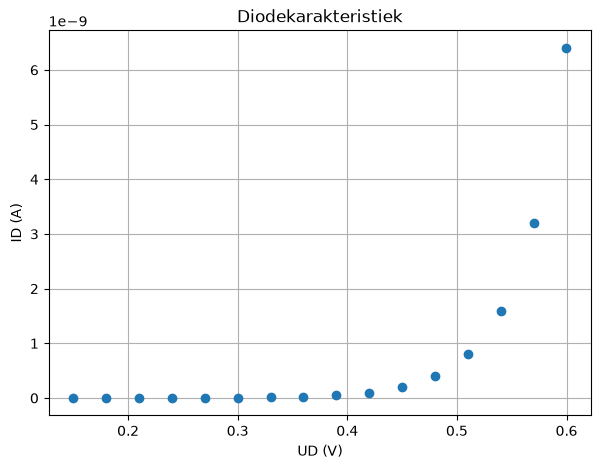

In [4]:
plt.figure(figsize=(7,5))
plt.plot(UD,ID,'o',markersize=6)
plt.xlabel("UD (V)")
plt.ylabel("ID (A)")
plt.title("Diodekarakteristiek")
plt.grid(True)
plt.show()

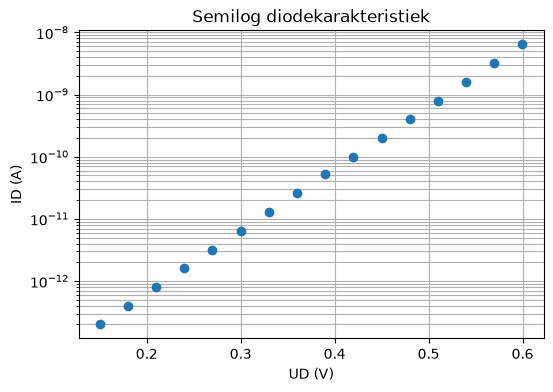

In [5]:
plt.figure(figsize=(6,4))
plt.semilogy(UD, ID, 'o')
plt.xlabel("UD (V)")
plt.ylabel("ID (A)")
plt.title("Semilog diodekarakteristiek")
plt.grid(True, which='both')
plt.show()

In [6]:
q = 1.602176634e-19
kB = 1.380649e-23
T = 293.15

def diode(V, I0, n):
    return I0 * (np.exp(q * V / (n * kB * T)) - 1)

guess = [1e-9, 2]

popt, pcov = curve_fit(diode,UD,ID,p0=guess,maxfev=10000)

I0 = popt[0]
n = popt[1]

uI0 = np.sqrt(pcov[0,0])
un = np.sqrt(pcov[1,1])

print(f"I0 = {I0:.3e} A")
print(f"u(I0) = {uI0:.3e} A")

print(f"n = {n:.3f}")
print(f"u(n) = {un:.3f}")

I0 = 6.051e-15 A
u(I0) = 1.662e-17 A
n = 1.712
u(n) = 0.000


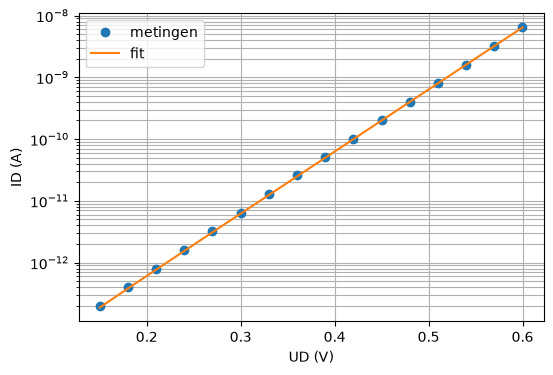

In [7]:
V_fit = np.linspace(min(UD), max(UD), 1000)
I_fit = diode(V_fit, I0, n)
plt.figure(figsize=(6,4))
plt.semilogy(UD, ID, 'o', label='metingen')
plt.semilogy(V_fit, I_fit, '-', label='fit')
plt.xlabel("UD (V)")
plt.ylabel("ID (A)")
plt.legend()
plt.grid(True, which='both')
plt.show()

**Describing the pattern in the processed data:**  
De stroom neemt exponentieel toe met de spanning over de diode. Op semilog-schaal liggen de punten ongeveer op een rechte lijn. De gemeten karakteristiek komt overeen met de theoretische diodevergelijking.

In [8]:
n_theory = 2.0
mask = ID > 0

UD_fit = UD[mask]
ID_fit2 = ID[mask]

y = np.log10(ID_fit2)

coef = np.polyfit(UD_fit, y, 1)

b = coef[0]

kB_exp = q * np.log10(np.e) / (n_theory * T * b)

print(f"b = {b:.4f}")
print(f"kB = {kB_exp:.4e} J/K")

kB_lit = 1.380649e-23

verschil = abs(kB_exp - kB_lit) / kB_lit * 100

print(f"Afwijking = {verschil:.2f} %")


b = 10.0024
kB = 1.1865e-23 J/K
Afwijking = 14.06 %


**Notes:**  

# Discussion
Mogelijke foutbronnen:
- onzekerheid weerstand
- onnauwkeurigheid DMM
- temperatuur niet exact bekend
- idealiteitsfactor diode


# Conclusion
Uit de gemeten I-V karakteristiek werd een waarde voor de Boltzmannconstante bepaald van:

kB = ... ± ...

Deze komt (wel/niet) overeen met de literatuurwaarde binnen de meetonzekerheid.

# Additional notes, remarks, explanations, thoughts etc